## TASK 1 – Install Python, OpenCV and required libraries
**Objective:** Prepare the Colab environment for image processing, video processing and YOLO-based detection.

In [ ]:
# TASK 1: Install required libraries
!pip -q install ultralytics opencv-python-headless matplotlib pandas

In [ ]:
# TASK 1: Import libraries and verify the environment
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO
from google.colab import files
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from collections import defaultdict, deque
import time, math, os

print("Python:", sys.version.split()[0])
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Environment is ready!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python: 3.13.18
OpenCV: 5.0.0
NumPy: 2.4.6
Pandas: 2.2.3
Environment is ready!


## TASK 2 – Capture an image of a traffic signal using a camera
**Objective:** Capture a still image using the browser camera in Colab. Allow camera permission when your browser asks.

If you do not have a webcam, skip this task and upload a traffic image in Task 3.

In [ ]:
# TASK 2: Capture one image using the browser webcam
# Colab browser camera access is used instead of cv2.VideoCapture(0).

def take_photo(filename='traffic_camera_capture.jpg', quality=0.8):
    js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture photo';
      div.appendChild(capture);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      await new Promise((resolve) => capture.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

# Run this cell and click "Capture photo" in the camera preview.
# If camera permission is denied, use the image-upload cell in Task 3.
try:
    camera_image_path = take_photo()
    print("Photo saved as:", camera_image_path)
except Exception as e:
    print("Camera capture was not completed:", e)
    print("You can upload a traffic image in Task 3 instead.")

<IPython.core.display.Javascript object>

Camera capture was not completed: NotAllowedError: Permission denied
You can upload a traffic image in Task 3 instead.


## TASK 3 – Read and display traffic images using OpenCV
**Objective:** Upload a traffic image and display it using OpenCV/Matplotlib.

Saving Bustling Indian Traffic Junction.png to Bustling Indian Traffic Junction.png


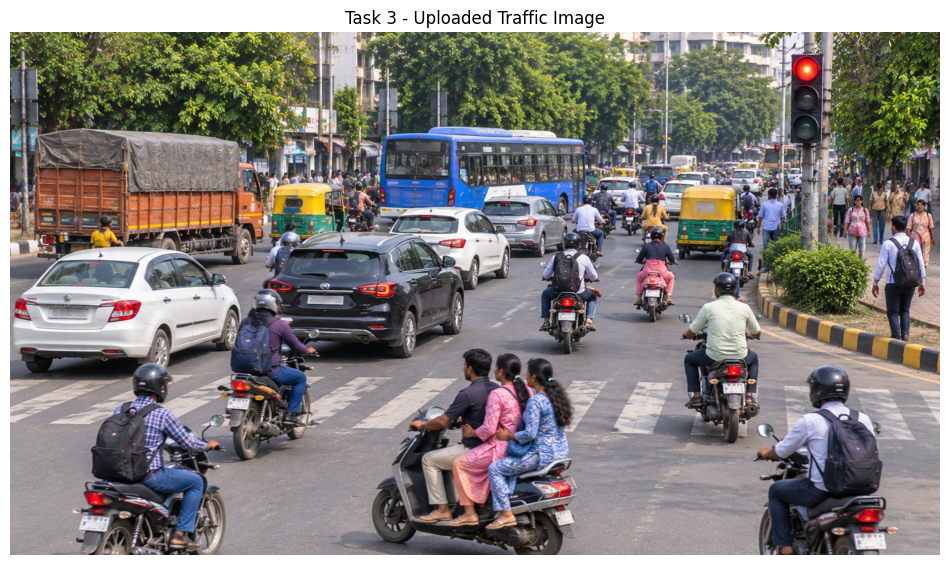

In [ ]:
# TASK 3: Upload and display a traffic image
uploaded_images = files.upload()  # Choose JPG, JPEG or PNG
image_path = next(iter(uploaded_images)) if uploaded_images else None

if image_path:
    traffic_image = cv2.imread(image_path)
    if traffic_image is None:
        raise ValueError("OpenCV could not read the uploaded image.")
    traffic_image_rgb = cv2.cvtColor(traffic_image, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 7))
    plt.imshow(traffic_image_rgb)
    plt.title("Task 3 - Uploaded Traffic Image")
    plt.axis("off")
    plt.show()
else:
    print("No image uploaded. Run this cell again and choose a traffic image.")

## TASK 4 – Load and play a traffic video using OpenCV
**Objective:** Upload a traffic video and preview it in the notebook.

In [ ]:
# TASK 4: Upload a traffic video
uploaded_videos = files.upload()  # Choose MP4, AVI or MOV
video_path = next(iter(uploaded_videos)) if uploaded_videos else None

if video_path:
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise ValueError("Could not open the uploaded video.")
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    print(f"Video: {width}x{height}, FPS: {fps:.2f}, Frames: {frame_count}")
    cap.release()
    from IPython.display import Video
    display(Video(video_path, embed=True))
else:
    print("No video uploaded. Upload a traffic video to continue.")

## TASK 5 – Extract individual frames from traffic videos
**Objective:** Save selected frames from the uploaded video as image files.

Extracted 14 frames successfully!


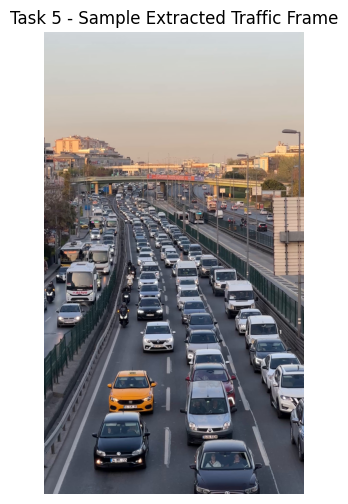

In [ ]:

# TASK 5: Extract individual frames from traffic videos

import os
import cv2
import matplotlib.pyplot as plt

os.makedirs("extracted_frames", exist_ok=True)

if video_path:
    cap = cv2.VideoCapture(video_path)

    frame_number = 0
    saved_count = 0
    frame_interval = 30

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        if frame_number % frame_interval == 0:
            output_name = f"extracted_frames/frame_{frame_number:05d}.jpg"
            cv2.imwrite(output_name, frame)
            saved_count += 1

        frame_number += 1

    cap.release()

    print(f"Extracted {saved_count} frames successfully!")

    # Display one extracted frame
    frame_files = sorted(os.listdir("extracted_frames"))

    if frame_files:
        sample_path = os.path.join("extracted_frames", frame_files[0])
        sample = cv2.imread(sample_path)

        if sample is not None:
            sample_rgb = cv2.cvtColor(sample, cv2.COLOR_BGR2RGB)

            plt.figure(figsize=(10, 6))
            plt.imshow(sample_rgb)
            plt.title("Task 5 - Sample Extracted Traffic Frame")
            plt.axis("off")
            plt.show()
        else:
            print("Unable to read the extracted frame.")

else:
    print("Please upload a traffic video in Task 4.")


## TASK 6 – Detect cars in a traffic video using YOLO
**Objective:** Run a pretrained YOLO model on video frames and detect cars.

The next cell loads a pretrained COCO model. The model weights download automatically the first time it runs.

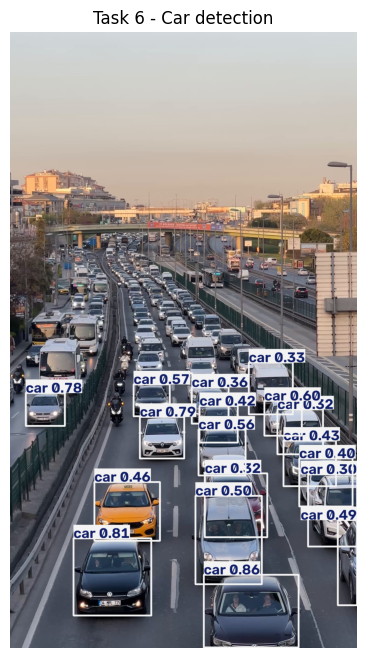

In [ ]:
# TASK 6: Load YOLO and detect cars in one video frame
model = YOLO("yolov8n.pt")  # Lightweight pretrained model

# COCO class IDs: car=2, motorcycle=3, bus=5, truck=7, person=0, traffic light=9
VEHICLE_CLASSES = [2, 3, 5, 7]
CLASS_NAMES = {0:"person", 2:"car", 3:"motorcycle", 5:"bus", 7:"truck", 9:"traffic light"}

def detect_frame(frame, classes=None, conf=0.25):
    results = model.predict(frame, conf=conf, classes=classes, verbose=False)
    return results[0].plot(), results[0]

if video_path:
    cap = cv2.VideoCapture(video_path)
    ret, frame = cap.read()
    cap.release()
    if ret:
        annotated, result = detect_frame(frame, classes=[2])
        plt.figure(figsize=(14, 8))
        plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
        plt.title("Task 6 - Car detection")
        plt.axis("off")
        plt.show()
    else:
        print("Could not read a frame from the video.")
else:
    print("Run Task 4 first and upload a video.")

## TASK 7 – Detect bikes, buses and trucks
**Objective:** Detect multiple vehicle categories: cars, motorcycles, buses and trucks.

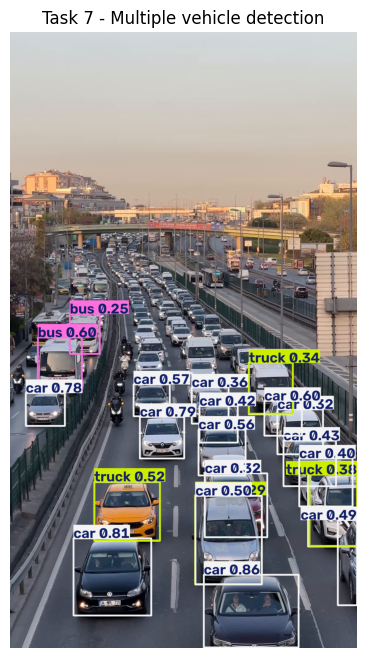

In [ ]:
# TASK 7: Detect multiple vehicle types in a video frame
if video_path:
    cap = cv2.VideoCapture(video_path)
    ret, frame = cap.read()
    cap.release()
    if ret:
        annotated, result = detect_frame(frame, classes=VEHICLE_CLASSES)
        plt.figure(figsize=(14, 8))
        plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
        plt.title("Task 7 - Multiple vehicle detection")
        plt.axis("off")
        plt.show()
else:
    print("Run Task 4 first and upload a video.")

## TASK 8 – Display vehicle names and confidence scores
**Objective:** Show each detected vehicle class and its confidence score.

,Vehicle,Confidence
0,car,0.856
1,car,0.809
2,car,0.794
3,car,0.777
4,car,0.605
5,bus,0.600
6,car,0.572
7,car,0.559
8,truck,0.519
9,car,0.500


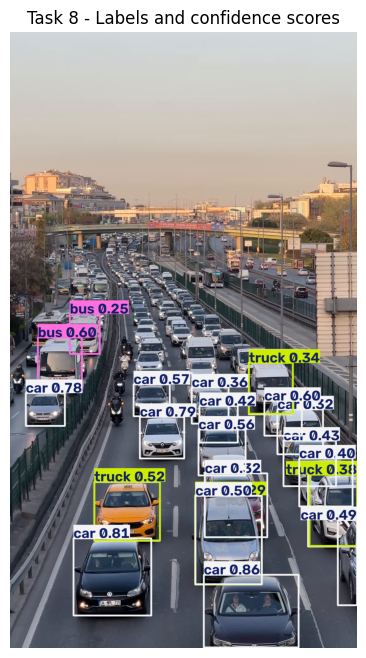

In [ ]:
# TASK 8: Display detected vehicle labels and confidence values
if video_path:
    cap = cv2.VideoCapture(video_path)
    ret, frame = cap.read()
    cap.release()
    if ret:
        results = model.predict(frame, conf=0.25, classes=VEHICLE_CLASSES, verbose=False)[0]
        rows = []
        for box in results.boxes:
            cls_id = int(box.cls[0])
            confidence = float(box.conf[0])
            rows.append({"Vehicle": CLASS_NAMES.get(cls_id, str(cls_id)),
                         "Confidence": round(confidence, 3)})
        display(pd.DataFrame(rows))
        annotated = results.plot()
        plt.figure(figsize=(14, 8))
        plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
        plt.title("Task 8 - Labels and confidence scores")
        plt.axis("off")
        plt.show()
else:
    print("Run Task 4 first and upload a video.")

## TASK 9 – Count the number of vehicles in a video frame
**Objective:** Count detected vehicles in a selected frame.

In [ ]:
# TASK 9: Count vehicles in a video frame
if video_path:
    cap = cv2.VideoCapture(video_path)
    ret, frame = cap.read()
    cap.release()
    if ret:
        result = model.predict(frame, conf=0.25, classes=VEHICLE_CLASSES, verbose=False)[0]
        vehicle_count = len(result.boxes)
        print("Total vehicles detected in this frame:", vehicle_count)
        display(pd.Series({CLASS_NAMES.get(int(b.cls[0]), "unknown"): 1 for b in result.boxes})
                .groupby(level=0).sum().rename("Count").to_frame())
else:
    print("Run Task 4 first and upload a video.")

Total vehicles detected in this frame: 24


,Count
bus,1
car,1
truck,1


## TASK 10 – Calculate traffic density based on vehicle count
**Objective:** Categorize traffic as low, medium or high using a simple configurable threshold.

These thresholds are demonstration values. Adjust them for your camera view and frame size.

In [ ]:
# TASK 10: Estimate traffic density from vehicle count
def traffic_density(count):
    if count <= 5:
        return "LOW"
    elif count <= 15:
        return "MEDIUM"
    return "HIGH"

if video_path:
    cap = cv2.VideoCapture(video_path)
    ret, frame = cap.read()
    cap.release()
    if ret:
        result = model.predict(frame, conf=0.25, classes=VEHICLE_CLASSES, verbose=False)[0]
        count = len(result.boxes)
        print("Vehicle count:", count)
        print("Traffic density:", traffic_density(count))
else:
    print("Run Task 4 first and upload a video.")

Vehicle count: 24
Traffic density: HIGH


## TASK 11 – Detect traffic congestion at signal junctions
**Objective:** Generate a basic congestion alert when the number of detected vehicles is above a threshold.

This is a count-based demonstration, not a complete junction-level congestion model.

In [ ]:
# TASK 11: Basic congestion alert
CONGESTION_THRESHOLD = 15  # Change according to the camera view

if video_path:
    cap = cv2.VideoCapture(video_path)
    ret, frame = cap.read()
    cap.release()
    if ret:
        result = model.predict(frame, conf=0.25, classes=VEHICLE_CLASSES, verbose=False)[0]
        count = len(result.boxes)
        if count >= CONGESTION_THRESHOLD:
            print("CONGESTION ALERT: High number of vehicles detected!")
        else:
            print("Traffic is not classified as congested.")
        print("Vehicles detected:", count)
else:
    print("Run Task 4 first and upload a video.")

CONGESTION ALERT: High number of vehicles detected!
Vehicles detected: 24


## TASK 12 – Track individual vehicles across video frames
**Objective:** Use YOLO tracking to assign persistent tracking IDs to vehicles.

This cell processes the uploaded video and displays a short annotated preview.

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 2 packages in 190ms
Prepared 1 package in 31ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



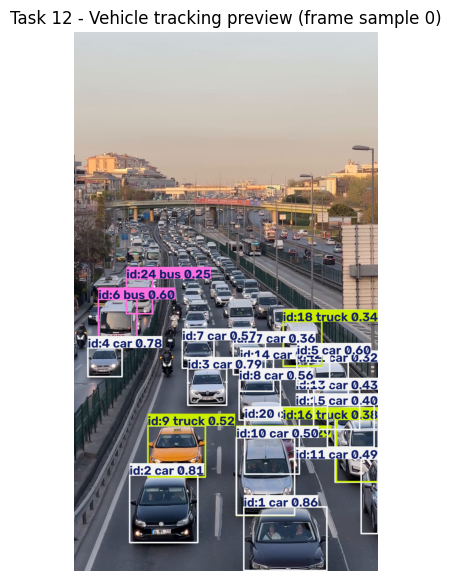

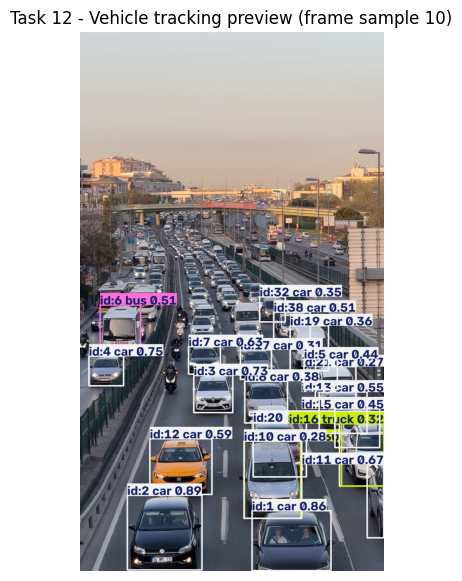

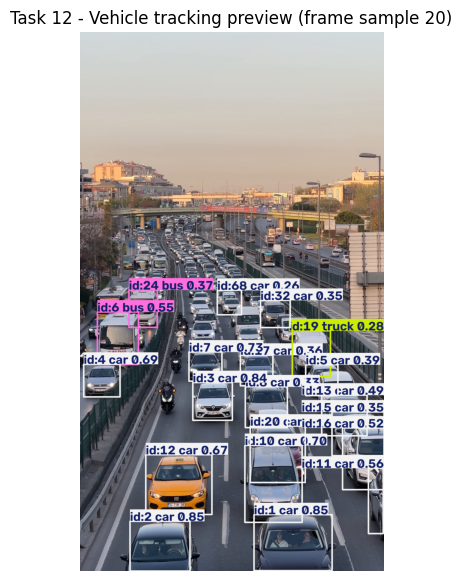

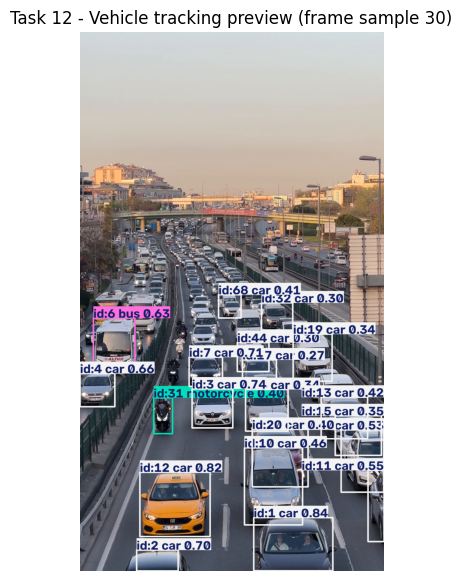

In [ ]:
# TASK 12: Track vehicles using ByteTrack (Ultralytics tracking)
# The tracker IDs are assigned by the tracking algorithm and may change after occlusion.
if video_path:
    tracking_results = model.track(
        source=video_path, classes=VEHICLE_CLASSES, conf=0.25,
        tracker="bytetrack.yaml", stream=True, persist=True, verbose=False
    )
    shown = 0
    for r in tracking_results:
        frame_annotated = r.plot()
        if shown % 10 == 0:  # Display every tenth processed frame
            plt.figure(figsize=(12, 7))
            plt.imshow(cv2.cvtColor(frame_annotated, cv2.COLOR_BGR2RGB))
            plt.title(f"Task 12 - Vehicle tracking preview (frame sample {shown})")
            plt.axis("off")
            plt.show()
        shown += 1
        if shown >= 31:
            break
else:
    print("Run Task 4 first and upload a video.")

## TASK 13 – Calculate approximate vehicle speed
**Objective:** Estimate speed from the movement of tracked vehicle centres between frames.

**Calibration required:** Set `PIXELS_PER_METER` using a known real-world distance visible on the road. The result is only an approximate estimate and is not suitable for enforcement.

In [ ]:

# TASK 13: Fast Approximate Vehicle Speed Estimation

import cv2
import math
import pandas as pd
from ultralytics import YOLO

# Load lightweight YOLO model
model = YOLO("yolov8n.pt")

# Camera calibration (adjust for your video)
PIXELS_PER_METER = 10.0

# Speed optimization settings
FRAME_SKIP = 5
MAX_FRAMES = 60

if video_path:

    cap = cv2.VideoCapture(video_path)

    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps <= 0:
        fps = 25.0

    previous_centres = {}
    speed_records = []

    frame_number = 0
    processed_frames = 0

    while processed_frames < MAX_FRAMES:

        ret, frame = cap.read()

        if not ret:
            break

        # Process only every 5th frame
        if frame_number % FRAME_SKIP == 0:

            results = model.track(
                frame,
                persist=True,
                classes=[2, 3, 5, 7],
                conf=0.35,
                tracker="bytetrack.yaml",
                verbose=False
            )[0]

            current_centres = {}

            if results.boxes is not None and results.boxes.id is not None:

                boxes = results.boxes.xyxy.cpu().numpy()
                ids = results.boxes.id.int().cpu().tolist()

                for box, track_id in zip(boxes, ids):

                    cx = (box[0] + box[2]) / 2
                    cy = (box[1] + box[3]) / 2

                    current_centres[track_id] = (cx, cy)

                    if track_id in previous_centres:

                        px, py = previous_centres[track_id]

                        distance_pixels = math.hypot(
                            cx - px, cy - py
                        )

                        distance_meters = (
                            distance_pixels / PIXELS_PER_METER
                        )

                        time_seconds = FRAME_SKIP / fps

                        speed = (
                            distance_meters / time_seconds
                        ) * 3.6

                        speed_records.append({
                            "Track ID": track_id,
                            "Speed (km/h)": round(speed, 2)
                        })

            previous_centres = current_centres

            processed_frames += 1

        frame_number += 1

    cap.release()

    print("Processed Frames:", processed_frames)

    if speed_records:

        df = pd.DataFrame(speed_records)

        display(df.head(20))

        print(
            "Average Estimated Speed:",
            round(df["Speed (km/h)"].mean(), 2),
            "km/h"
        )

    else:
        print("No vehicle speed samples detected.")

else:
    print("Please upload a traffic video in Task 4.")


Processed Frames: 60


,Track ID,Speed (km/h)
0,1,7.43
1,2,103.41
2,3,33.55
3,4,40.72
4,5,17.75
5,6,37.58
6,7,30.67
7,8,12.60
8,10,12.59
9,11,19.15


Average Estimated Speed: 26.15 km/h


## TASK 14 – Identify traffic signal status (red, yellow, green)
**Objective:** Detect the dominant signal colour inside a manually selected traffic-light region.

**Important:** Adjust the ROI coordinates to cover only the traffic signal in your image. This simple colour detector can be affected by sunlight, reflections and other bright objects.

In [ ]:
# TASK 14: Traffic light colour detection using HSV colour ranges
# Upload/choose an image if Task 3 was not completed.
if 'traffic_image' not in globals() or traffic_image is None:
    print("Upload and read a traffic image in Task 3 first.")
else:
    h, w = traffic_image.shape[:2]
    # EDIT THESE COORDINATES to the traffic light region: x1, y1, x2, y2
    x1, y1, x2, y2 = 0, 0, w, h
    roi = traffic_image[y1:y2, x1:x2]
    hsv = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)

    red1 = cv2.inRange(hsv, np.array([0, 100, 100]), np.array([10, 255, 255]))
    red2 = cv2.inRange(hsv, np.array([160, 100, 100]), np.array([180, 255, 255]))
    red_pixels = cv2.countNonZero(red1) + cv2.countNonZero(red2)
    yellow_pixels = cv2.countNonZero(cv2.inRange(hsv, np.array([15, 80, 100]), np.array([35, 255, 255])))
    green_pixels = cv2.countNonZero(cv2.inRange(hsv, np.array([40, 60, 60]), np.array([90, 255, 255])))

    scores = {"RED": red_pixels, "YELLOW": yellow_pixels, "GREEN": green_pixels}
    status = max(scores, key=scores.get)
    if scores[status] < 10:
        status = "UNKNOWN"
    print("Traffic signal status:", status)
    print("Colour pixel counts:", scores)

Traffic signal status: YELLOW
Colour pixel counts: {'RED': 51880, 'YELLOW': 69871, 'GREEN': 67256}


## TASK 15 – Estimate traffic waiting time
**Objective:** Estimate how long tracked vehicles remain nearly stationary.

This demo uses tracking IDs and centre-point movement. It is an approximate stopped-duration indicator, not a legal or calibrated waiting-time measurement.

In [ ]:
# TASK 15: Estimate stopped/waiting time for tracked vehicles
STOP_MOVEMENT_PIXELS = 3.0  # Maximum centre movement per frame to count as stopped
WAIT_VIDEO_LIMIT = 500

if video_path:
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    previous = {}
    stopped_start = {}
    waiting_report = {}
    idx = 0

    while idx < WAIT_VIDEO_LIMIT:
        ret, frame = cap.read()
        if not ret:
            break
        r = model.track(frame, persist=True, classes=VEHICLE_CLASSES,
                        tracker="bytetrack.yaml", conf=0.25, verbose=False)[0]
        now = {}
        if r.boxes is not None and r.boxes.id is not None:
            for box, tid in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.id.int().cpu().tolist()):
                center = ((box[0]+box[2])/2, (box[1]+box[3])/2)
                now[tid] = center
                if tid in previous:
                    movement = math.hypot(center[0]-previous[tid][0], center[1]-previous[tid][1])
                    if movement <= STOP_MOVEMENT_PIXELS:
                        stopped_start.setdefault(tid, idx)
                        waiting_report[tid] = (idx-stopped_start[tid])/fps
                    else:
                        stopped_start.pop(tid, None)
        previous = now
        idx += 1
    cap.release()
    if waiting_report:
        display(pd.DataFrame([{"Track ID": k, "Approx stopped time (seconds)": round(v, 2)}
                              for k, v in waiting_report.items()]))
    else:
        print("No stationary tracked vehicles detected in the processed frames.")
else:
    print("Run Task 4 first and upload a video.")

,Track ID,Approx stopped time (seconds)
0,143,2.84
1,145,0.00
2,147,0.05
3,150,0.15
4,157,0.10
...,...,...
86,977,0.05
87,996,0.00
88,983,0.10
89,975,0.00


## TASK 16 – Count vehicles entering and leaving a traffic junction
**Objective:** Count vehicles crossing a virtual line in either direction.

**Setup:** Adjust the line coordinates to a visible road crossing line in your video. Counts depend on camera angle and stable tracking.

In [ ]:
# TASK 16: Entry/exit counting using a virtual horizontal line
LINE_Y = 250  # EDIT for your video
LINE_X_MIN, LINE_X_MAX = 0, 99999
ENTRY_EXIT_LIMIT = 500

if video_path:
    cap = cv2.VideoCapture(video_path)
    last_side = {}
    entered, exited = set(), set()
    idx = 0
    while idx < ENTRY_EXIT_LIMIT:
        ret, frame = cap.read()
        if not ret:
            break
        r = model.track(frame, persist=True, classes=VEHICLE_CLASSES,
                        tracker="bytetrack.yaml", conf=0.25, verbose=False)[0]
        if r.boxes is not None and r.boxes.id is not None:
            for box, tid in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.id.int().cpu().tolist()):
                cx = (box[0]+box[2])/2
                cy = (box[1]+box[3])/2
                if not (LINE_X_MIN <= cx <= LINE_X_MAX):
                    continue
                side = "above" if cy < LINE_Y else "below"
                if tid in last_side and last_side[tid] != side:
                    if last_side[tid] == "above" and side == "below":
                        entered.add(tid)
                    elif last_side[tid] == "below" and side == "above":
                        exited.add(tid)
                last_side[tid] = side
        idx += 1
    cap.release()
    print("Vehicles entering (above to below):", len(entered))
    print("Vehicles leaving (below to above):", len(exited))
else:
    print("Run Task 4 first and upload a video.")

Vehicles entering (above to below): 0
Vehicles leaving (below to above): 0


## TASK 17 – Detect vehicles making wrong turns at intersections
**Objective:** Demonstrate a configurable path-based wrong-turn alert.

**Setup required:** Define the expected direction/path for your junction. This starter implementation checks whether a tracked vehicle's movement angle falls outside an allowed direction range. It does not understand all legal turning lanes automatically.

In [ ]:
# TASK 17: Basic wrong-turn direction deviation demo
# EDIT EXPECTED_ANGLE_DEG and ANGLE_TOLERANCE for the intended path.
EXPECTED_ANGLE_DEG = 0.0  # 0 degrees = moving right; 90 = down in image coordinates
ANGLE_TOLERANCE = 45.0
TURN_VIDEO_LIMIT = 500

def angle_difference(a, b):
    return abs((a - b + 180) % 360 - 180)

if video_path:
    cap = cv2.VideoCapture(video_path)
    previous = {}
    alerts = set()
    idx = 0
    while idx < TURN_VIDEO_LIMIT:
        ret, frame = cap.read()
        if not ret:
            break
        r = model.track(frame, persist=True, classes=VEHICLE_CLASSES,
                        tracker="bytetrack.yaml", conf=0.25, verbose=False)[0]
        current = {}
        if r.boxes is not None and r.boxes.id is not None:
            for box, tid in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.id.int().cpu().tolist()):
                center = ((box[0]+box[2])/2, (box[1]+box[3])/2)
                current[tid] = center
                if tid in previous:
                    dx = center[0]-previous[tid][0]
                    dy = center[1]-previous[tid][1]
                    if math.hypot(dx, dy) > 5:
                        angle = math.degrees(math.atan2(dy, dx))
                        if angle_difference(angle, EXPECTED_ANGLE_DEG) > ANGLE_TOLERANCE:
                            alerts.add(tid)
        previous = current
        idx += 1
    cap.release()
    print("Potential wrong-turn / unexpected-direction track IDs:", sorted(alerts))
    print("Tune the expected path and tolerance for the selected junction.")
else:
    print("Run Task 4 first and upload a video.")

Potential wrong-turn / unexpected-direction track IDs: [973, 1020, 1024, 1040, 1369, 1458, 1568, 1679, 1719, 1844, 1875, 1885, 1886, 1887, 1889, 1891, 1892, 1894, 1895, 1900, 1903, 1904, 1909, 1910, 1911, 1917, 1923, 1931, 1946, 1972, 1995, 2018, 2048, 2058, 2064, 2067, 2069, 2086, 2099, 2111, 2112, 2134, 2135, 2142, 2146, 2162, 2207, 2216, 2219, 2235, 2240, 2306, 2313, 2318, 2324, 2329, 2331, 2362, 2363, 2372, 2373, 2376, 2377, 2379, 2381, 2402, 2412, 2429, 2439, 2454, 2464, 2470, 2471, 2492, 2494, 2525, 2537, 2545, 2550, 2590, 2606, 2676, 2688, 2715, 2717, 2719, 2725, 2741]
Tune the expected path and tolerance for the selected junction.


## TASK 18 – Identify vehicles moving in the wrong direction
**Objective:** Flag tracked vehicles whose movement is opposite to the expected road direction.

**Setup:** Set `EXPECTED_ROAD_DIRECTION_DEG` to the normal direction of travel for your camera view.

In [ ]:
# TASK 18: Wrong-way movement detection
EXPECTED_ROAD_DIRECTION_DEG = 0.0  # EDIT for your video
WRONG_WAY_TOLERANCE = 45.0
WRONG_WAY_LIMIT = 500

if video_path:
    cap = cv2.VideoCapture(video_path)
    previous = {}
    wrong_way_ids = set()
    idx = 0
    while idx < WRONG_WAY_LIMIT:
        ret, frame = cap.read()
        if not ret:
            break
        r = model.track(frame, persist=True, classes=VEHICLE_CLASSES,
                        tracker="bytetrack.yaml", conf=0.25, verbose=False)[0]
        current = {}
        if r.boxes is not None and r.boxes.id is not None:
            for box, tid in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.id.int().cpu().tolist()):
                c = ((box[0]+box[2])/2, (box[1]+box[3])/2)
                current[tid] = c
                if tid in previous:
                    dx, dy = c[0]-previous[tid][0], c[1]-previous[tid][1]
                    if math.hypot(dx, dy) > 5:
                        direction = math.degrees(math.atan2(dy, dx))
                        opposite = (EXPECTED_ROAD_DIRECTION_DEG + 180) % 360
                        if angle_difference(direction, opposite) <= WRONG_WAY_TOLERANCE:
                            wrong_way_ids.add(tid)
        previous = current
        idx += 1
    cap.release()
    print("Potential wrong-way vehicle track IDs:", sorted(wrong_way_ids))
else:
    print("Run Task 4 first and upload a video.")

Potential wrong-way vehicle track IDs: [1891, 1895, 2439, 2550, 2590, 2746, 2756, 2758, 2760, 2762, 2763, 2766, 2774, 2775, 2780, 2781, 2782, 2788, 2794, 2802, 2843, 2866, 2919, 2982, 3005, 3013, 3087, 3106, 3111, 3177, 3189, 3200, 3202, 3233, 3243, 3247, 3250, 3283, 3310, 3335, 3341, 3342, 3363, 3365, 3408, 3421, 3461, 3477, 3547, 3586, 3590, 3612]


## TASK 19 – Detect vehicles parked in restricted traffic areas
**Objective:** Identify vehicles that remain inside a user-defined restricted polygon for a minimum duration.

**Setup required:** Edit the polygon points to match the restricted area in your camera frame. This simple demo treats a vehicle as present when its centre is inside the polygon.

In [ ]:
# TASK 19: Restricted-area parking detection
# EDIT polygon coordinates to match the restricted road area in your video.
RESTRICTED_POLYGON = np.array([[100, 100], [400, 100], [400, 300], [100, 300]], dtype=np.int32)
PARKED_SECONDS = 5
PARK_LIMIT = 500

if video_path:
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    inside_since = {}
    alerts = {}
    idx = 0
    while idx < PARK_LIMIT:
        ret, frame = cap.read()
        if not ret:
            break
        r = model.track(frame, persist=True, classes=VEHICLE_CLASSES,
                        tracker="bytetrack.yaml", conf=0.25, verbose=False)[0]
        seen_inside = set()
        if r.boxes is not None and r.boxes.id is not None:
            for box, tid in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.id.int().cpu().tolist()):
                cx, cy = int((box[0]+box[2])/2), int((box[1]+box[3])/2)
                if cv2.pointPolygonTest(RESTRICTED_POLYGON, (cx, cy), False) >= 0:
                    seen_inside.add(tid)
                    inside_since.setdefault(tid, idx)
                    duration = (idx-inside_since[tid])/fps
                    if duration >= PARKED_SECONDS:
                        alerts[tid] = round(duration, 2)
        for tid in list(inside_since):
            if tid not in seen_inside:
                inside_since.pop(tid, None)
        idx += 1
    cap.release()
    print("Restricted-area vehicle alerts (Track ID: seconds):", alerts)
    print("Adjust RESTRICTED_POLYGON before interpreting results.")
else:
    print("Run Task 4 first and upload a video.")

Restricted-area vehicle alerts (Track ID: seconds): {}
Adjust RESTRICTED_POLYGON before interpreting results.


## TASK 20 – Detect two-wheelers carrying more than two persons
**Objective:** Detect motorcycles and people, then flag motorcycles with more than two nearby person detections.

**Important limitation:** COCO YOLO detects people and motorcycles separately. This proximity-based method can miscount people on nearby bikes, pedestrians, or overlapping vehicles. For stronger results, use a dedicated rider/passenger dataset and train or fine-tune a model.

Possible triple-riding motorcycles: 0


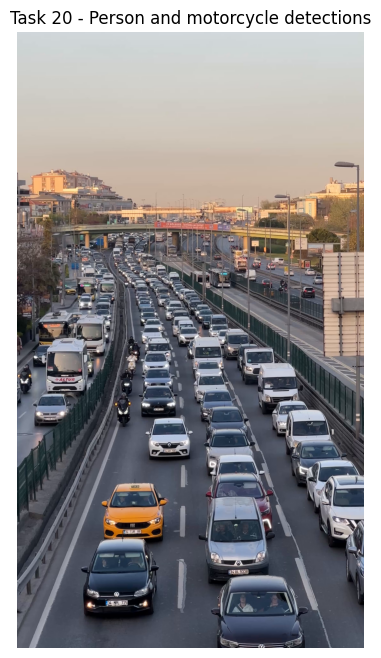

In [ ]:
# TASK 20: Heuristic triple-riding detection
# A person is associated with a motorcycle if the person's box centre lies
# within an expanded motorcycle bounding box.
def point_in_expanded_box(point, box, expand_x=0.25, expand_y=0.35):
    x1, y1, x2, y2 = box
    pad_x = (x2-x1)*expand_x
    pad_y = (y2-y1)*expand_y
    x, y = point
    return (x1-pad_x <= x <= x2+pad_x) and (y1-pad_y <= y <= y2+pad_y)

if video_path:
    cap = cv2.VideoCapture(video_path)
    ret, frame = cap.read()
    cap.release()
    if ret:
        result = model.predict(frame, conf=0.25, classes=[0, 3], verbose=False)[0]
        person_centres = []
        motorcycle_boxes = []
        for box in result.boxes:
            cls_id = int(box.cls[0])
            xyxy = box.xyxy[0].cpu().numpy()
            if cls_id == 0:
                person_centres.append(((xyxy[0]+xyxy[2])/2, (xyxy[1]+xyxy[3])/2))
            elif cls_id == 3:
                motorcycle_boxes.append(xyxy)

        triple_count = 0
        for bike_index, bike_box in enumerate(motorcycle_boxes, start=1):
            associated_people = [p for p in person_centres if point_in_expanded_box(p, bike_box)]
            person_count = len(associated_people)
            print(f"Motorcycle {bike_index}: nearby person detections = {person_count}")
            if person_count > 2:
                triple_count += 1
                print("  ALERT: Possible triple riding detected!")
        print("Possible triple-riding motorcycles:", triple_count)

        annotated = result.plot()
        plt.figure(figsize=(14, 8))
        plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
        plt.title("Task 20 - Person and motorcycle detections")
        plt.axis("off")
        plt.show()
    else:
        print("Could not read a frame from the uploaded video.")
else:
    print("Run Task 4 first and upload a video.")